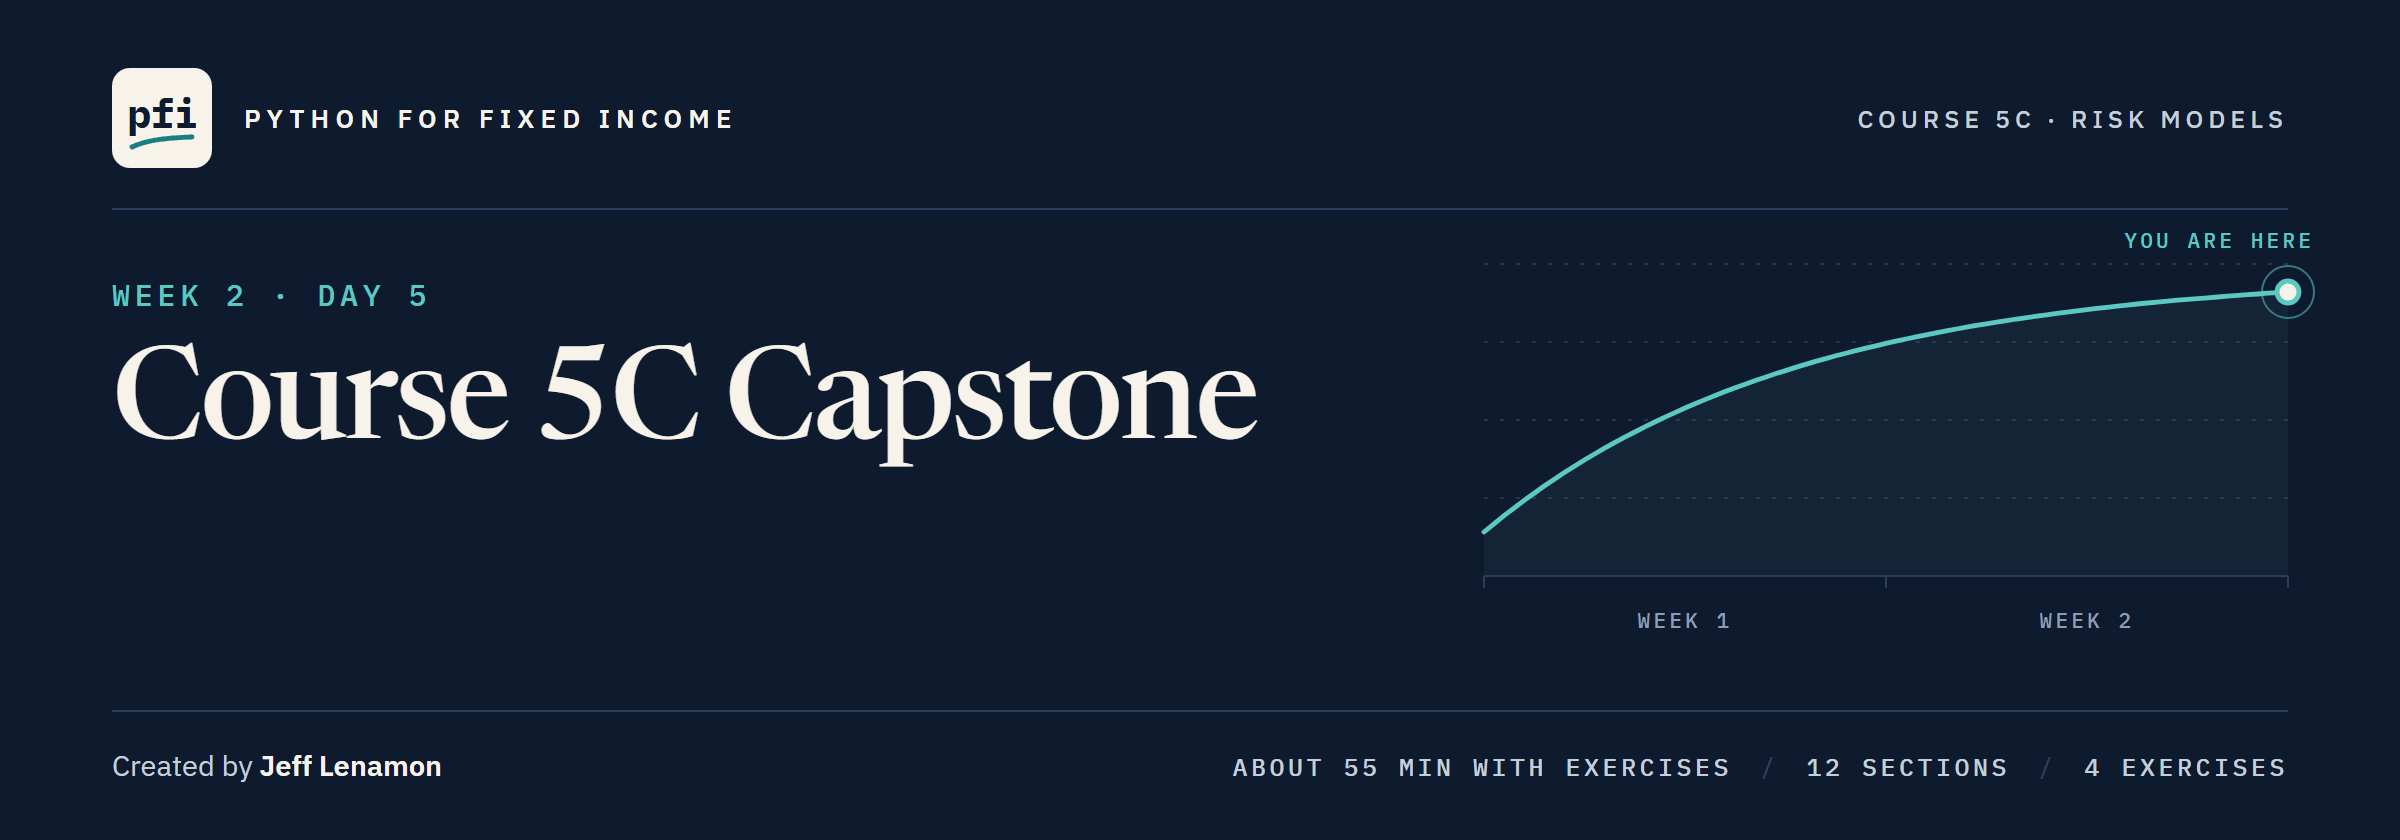

# Course 5C Capstone

Week 2, Day 5. Build a risk report on the development rows, write every choice down, then open the held-out years once and say what held.

**Data:** `holdings.csv`, the course's book of 200 bonds as of 2026-09-30, with `ratings.csv` for the rating scale: **synthetic**, invented issuers and CUSIPs, no real company.

**Data:** `treasury_par_yields.csv`, 2,940 days of U.S. Treasury par yields, 2015-01-02 to 2026-10-02: **real**, U.S. Department of the Treasury, public domain.

**Data:** `course3_synthetic_spreads.csv`, 2,940 daily investment grade and high yield spreads in bp, one per date of the Treasury file: **synthetic**, invented for Course 3, not ICE, Moody's, or any index.

**Data:** `trade_blotter.csv`, the desk's 374 trades in September 2026 in bonds of the book: **synthetic**, invented trades and counterparties.

**Data:** `course5c_cohort.csv`, 4,000 invented firms followed year by year over 20 study years to default, exit, or the end: **synthetic**, ids only, no calendar years, and no agency default statistic.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05c_risk_models/week2/day5/course5c_capstone.ipynb)

# Problem Statement

## Business Context

The risk team wants one report on the synthetic book, 200 bonds worth US$490.8m as of 2026-09-30, and on the synthetic cohort of firms.
It has five pieces: the book's market risk (Day 2), its credit loss (Day 3), a hazard model (Day 5), a screen of September's trades (Day 6), and drift (Day 8) read with Day 9's bands.
Every choice is made on the development rows, 2015 to 2022 and study years 1 to 14, and printed; then the held-out rows are opened once.
A VaR describes past days replayed on today's book, a credit loss invented inputs, and a flag a print to check: never what the book will lose.
Each question has an empty cell and a `check()` line.

## Objectives

Repeat the book's historical VaR and its credit loss, with each percentile's precision.
Choose a hazard model by a rule written first, and score a screen of planted prints.
Open the held-out years once, score each piece there, and measure drift with PSI.

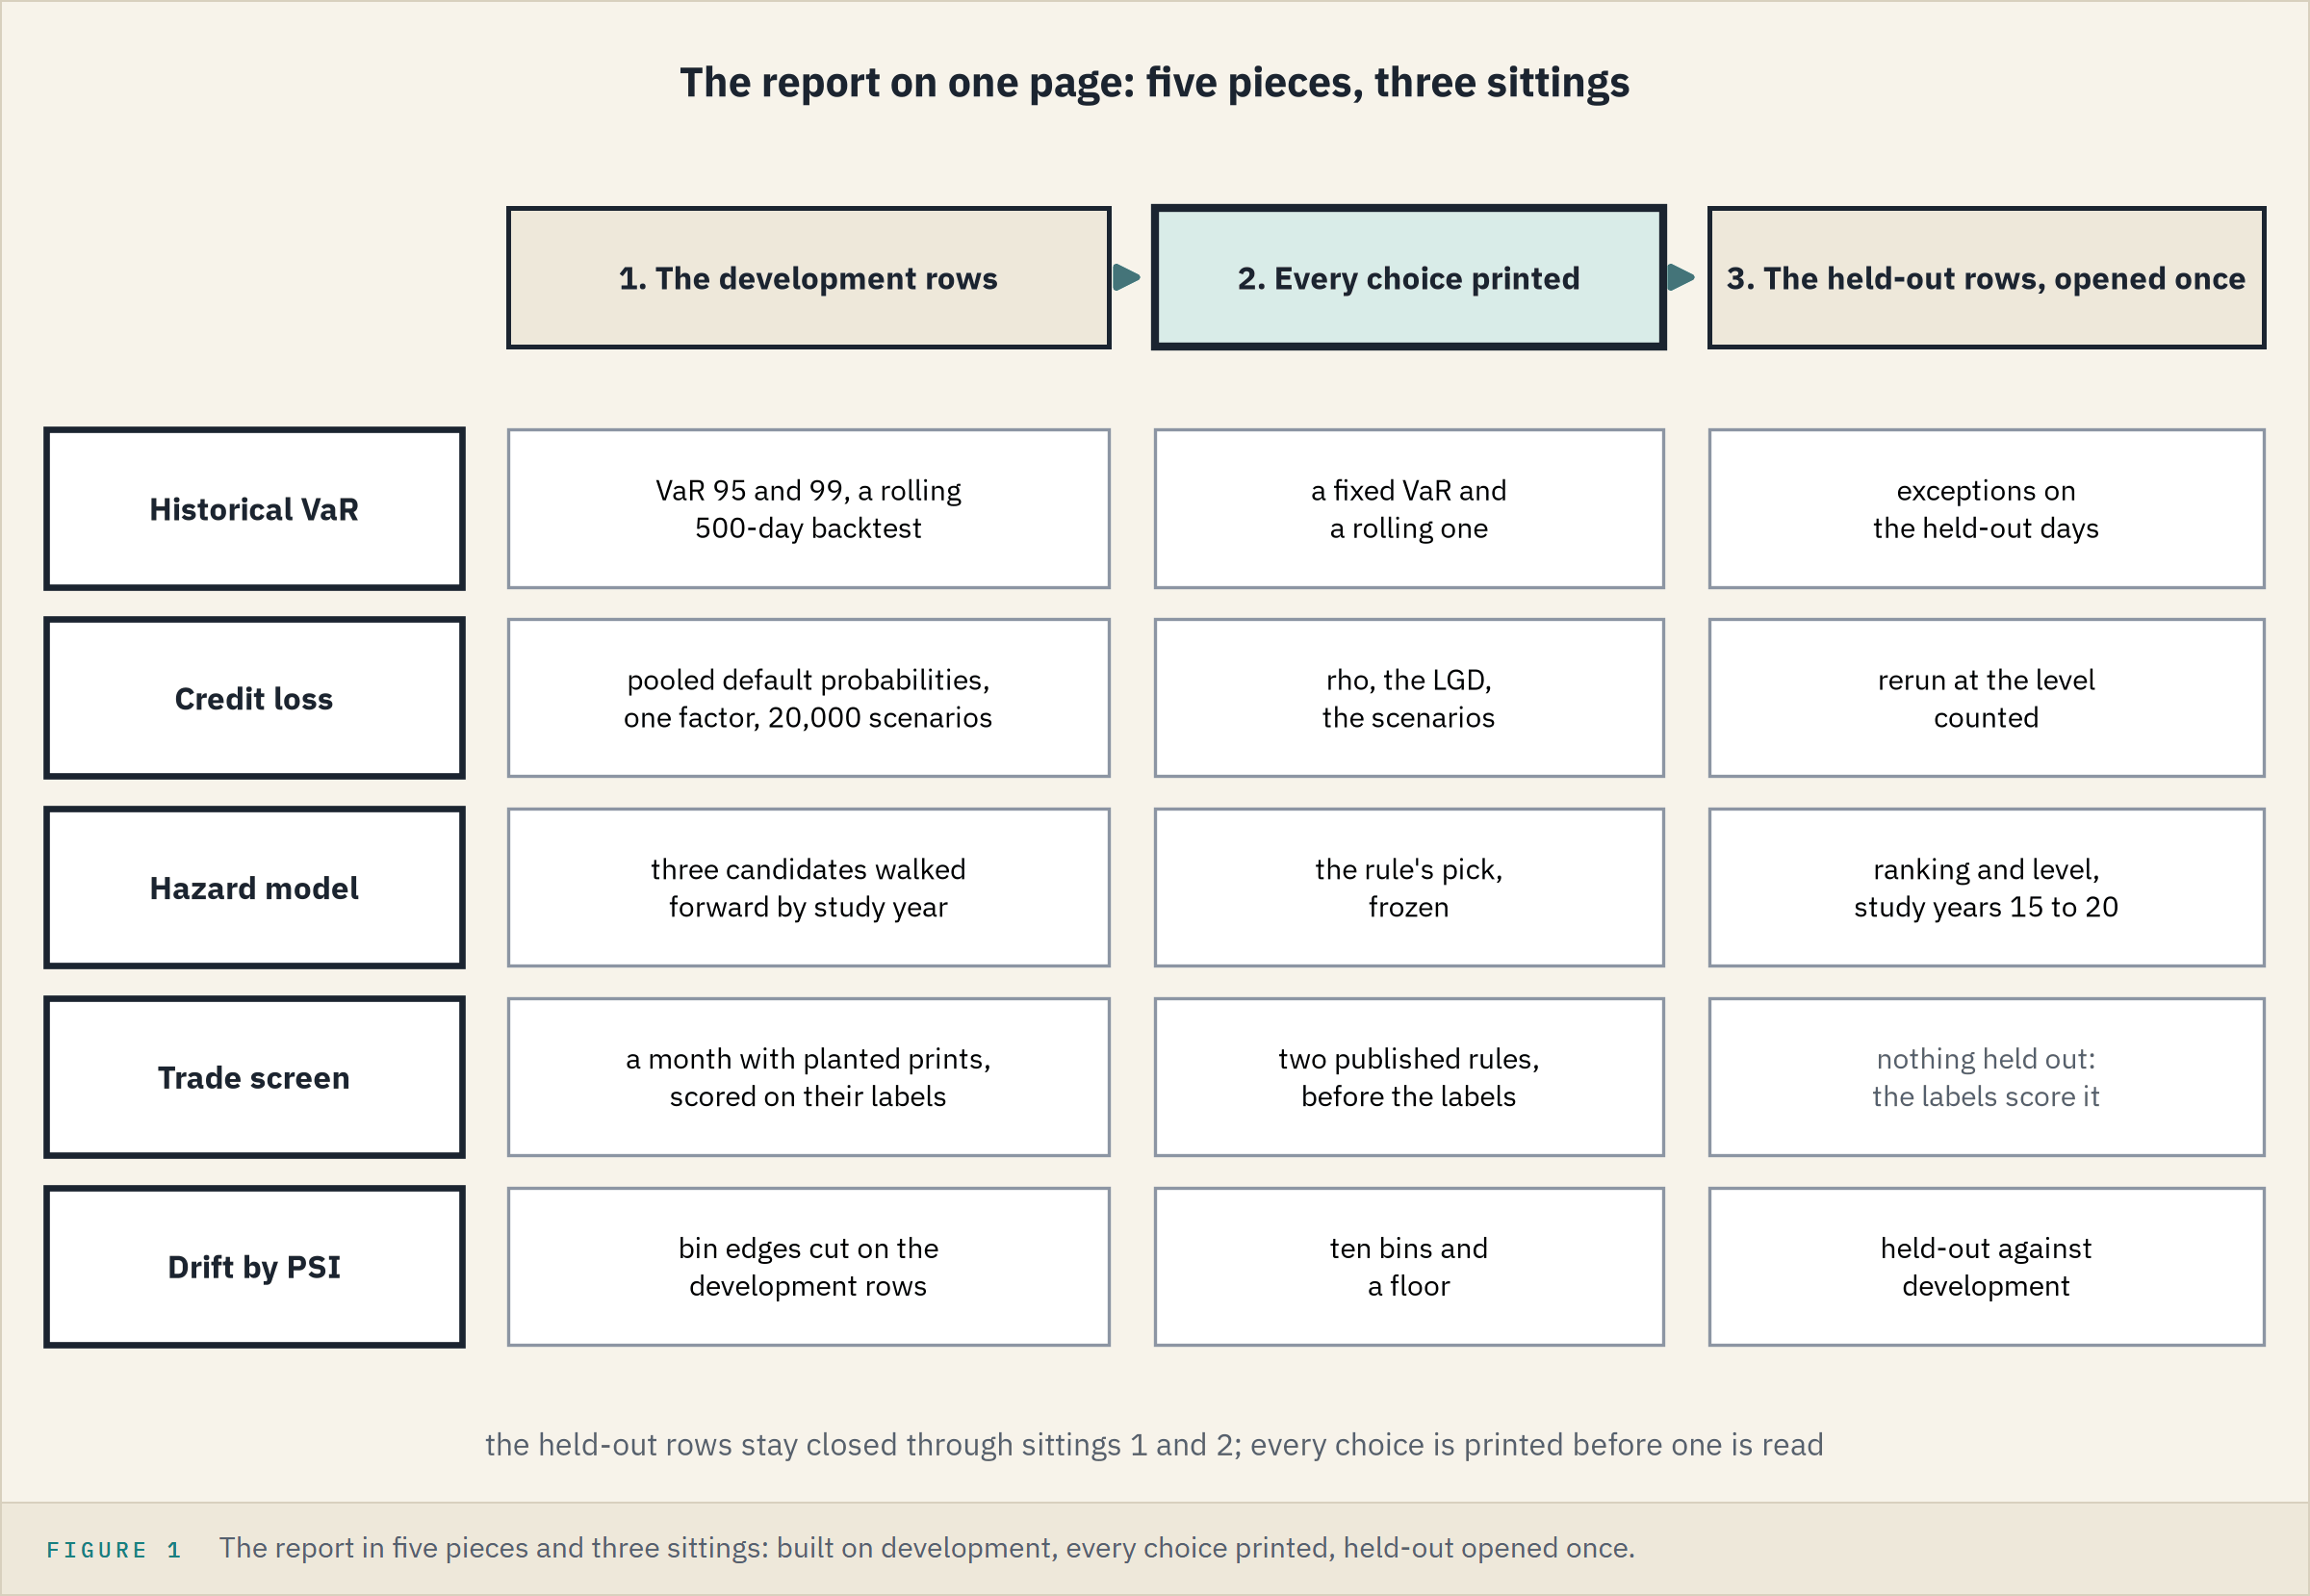

## Data Dictionary

`holdings.csv` with `ratings.csv`: each bond's `rating`, `oas` (bp), durations (years) and `market_value` (US$).
`treasury_par_yields.csv`: par yields in percent; `course3_synthetic_spreads.csv`: two spreads in bp.
`trade_blotter.csv`: one row a trade, with its `price`.
`course5c_cohort.csv`: one row a firm-year, with `rating_score`, `leverage`, `coverage` and `default`.

## Your Route Through Day 5

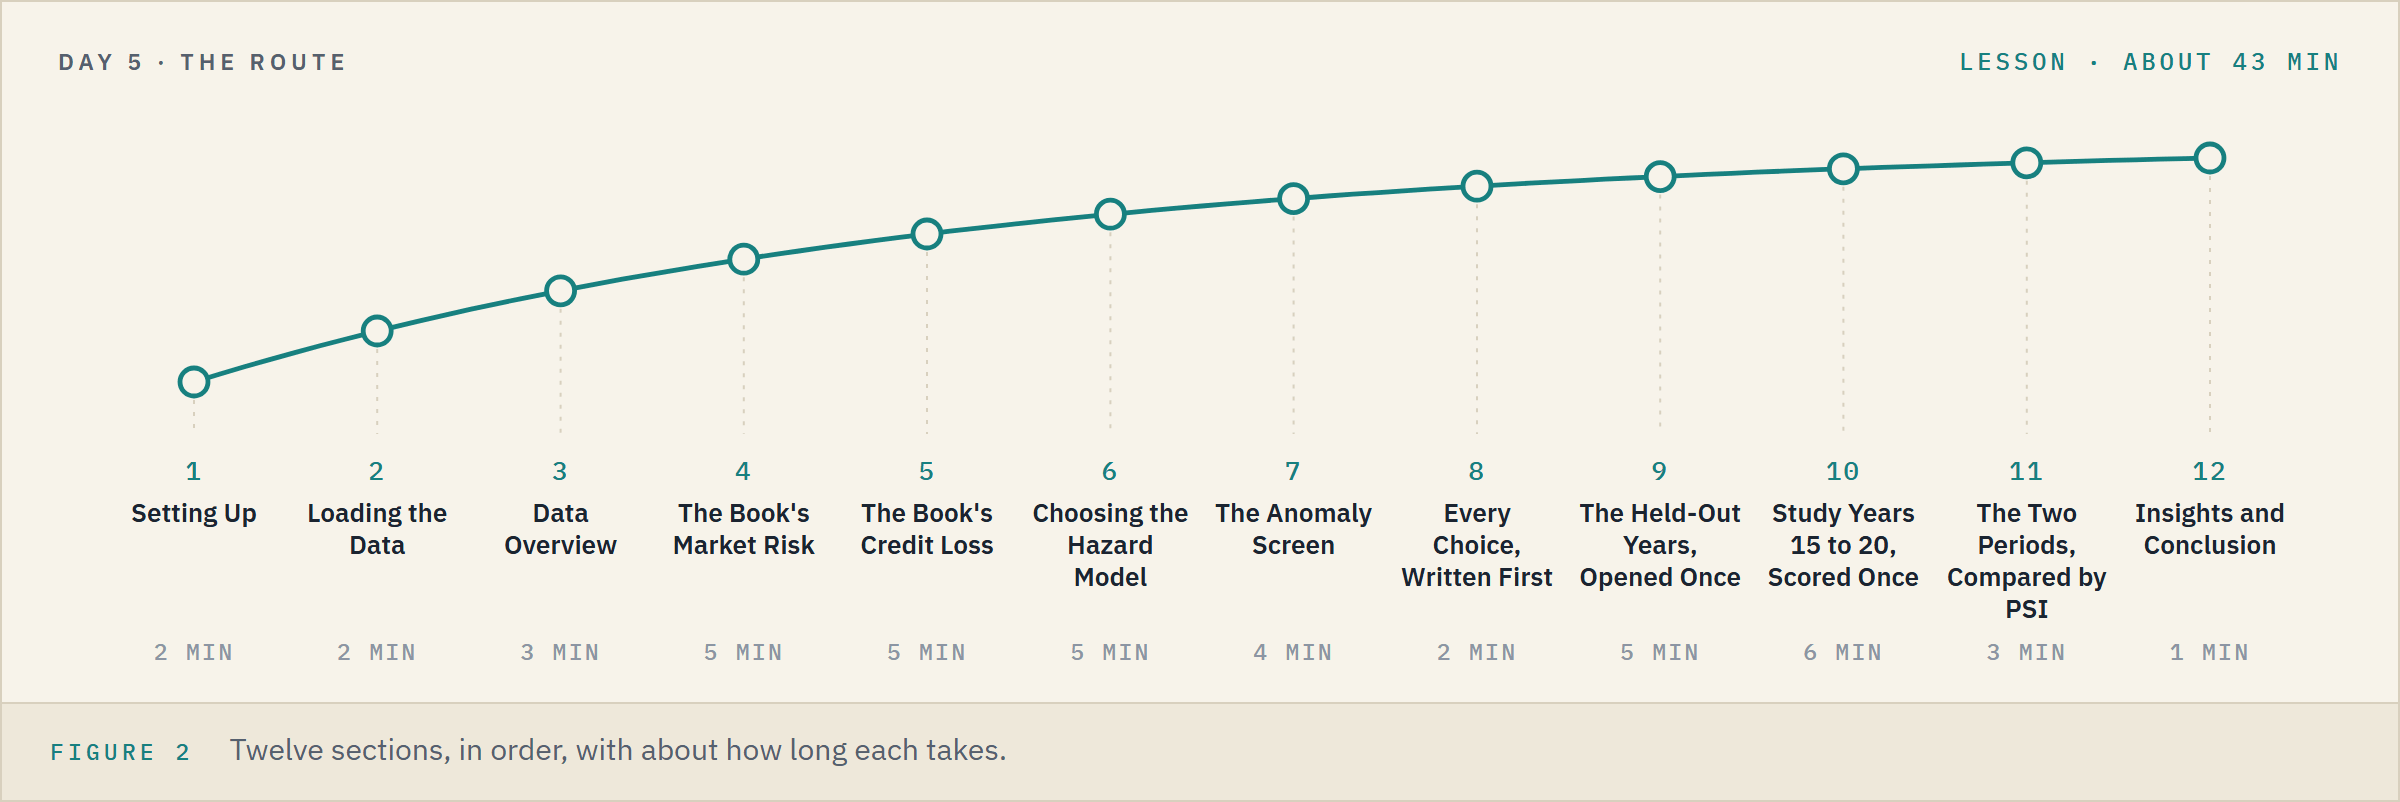

**Time.** About 43 minutes for the lesson, then about 12 for the four exercises.

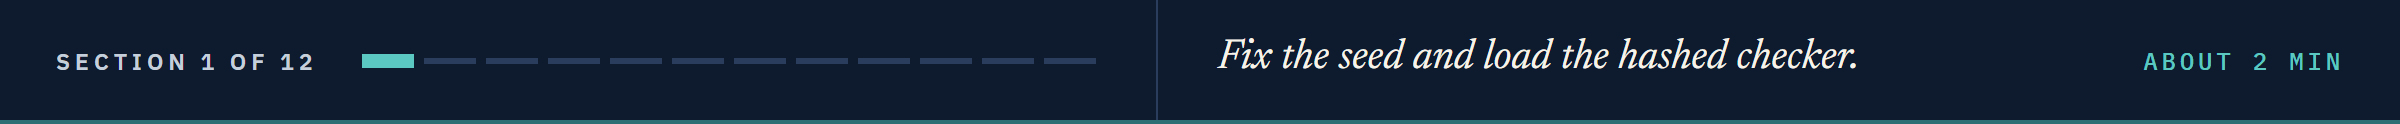

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# to load and work with the data
import numpy as np
import pandas as pd

# the normal, binomial, chi-squared and Poisson curves, and the logistic fit
from scipy import stats
import statsmodels.api as sm

# the AUC (Course 4's Day 8) and the screen's scores (Day 6)
from sklearn.metrics import roc_auc_score, confusion_matrix, precision_score, recall_score, f1_score

# to draw charts
import matplotlib.pyplot as plt
import seaborn as sns

# one look for every chart
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
# one colour for each of the four kinds of row a confusion matrix counts
CELL_COLOURS = {"TN": "#56B4E9", "FP": "#DE8F05", "FN": "#D55E00", "TP": "#0173B2"}
plt.rcParams["figure.figsize"] = (10, 5)

## The Answer Checker

`check()` compares a fingerprint of each answer with a stored one, so no answer is on the page; a US$ sum is checked to the dollar.

In [3]:
# check() compares a fingerprint of your answer with a stored one, so no answer is written on the page
import hashlib


def check(label, answer, code, places=None):
    if answer is ...:
        print(label + ": not attempted yet")
        return
    # a number is rounded to the places the question asks for, so 0.66241 and 0.6624 read the same
    if places is not None:
        answer = round(float(answer), places)
    text = label + "|" + str(answer).strip().lower()
    # hashlib.sha256() makes a fingerprint that cannot be turned back into the answer;
    # .encode() turns the text into bytes for it, and .hexdigest() writes it as letters and digits
    if hashlib.sha256(text.encode()).hexdigest()[:12] == code:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have " + str(answer))

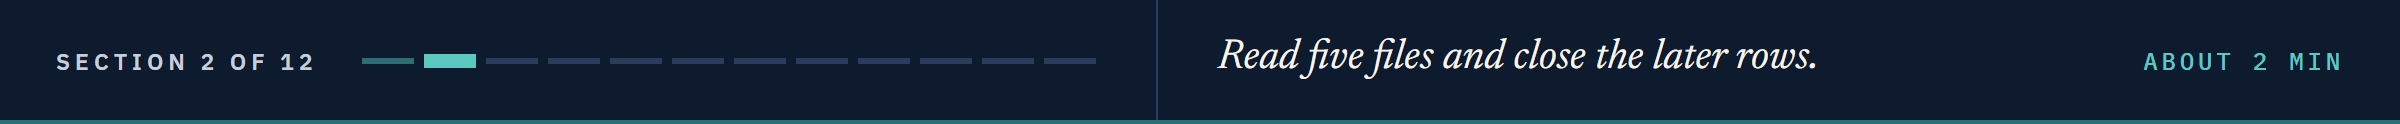

# Loading the Data

## The Five Files and the Two Cuts

In [4]:
# the book of 200 synthetic bonds as of 2026-09-30, with each bond's score, bucket and grade from the rating scale
book = pd.read_csv(DATA + "holdings.csv")
ratings = pd.read_csv(DATA + "ratings.csv")
book = book.merge(ratings[["rating", "score", "bucket", "grade"]], on="rating")
book["years_to_maturity"] = (pd.to_datetime(book["maturity"]) - pd.to_datetime(book["as_of_date"])).dt.days / 365.25

In [5]:
# the Treasury par yields (percent), eight tenors named by their years, and the synthetic spreads (bp)
treasury = pd.read_csv(DATA + "treasury_par_yields.csv", parse_dates=["date"], index_col="date")
spreads = pd.read_csv(DATA + "course3_synthetic_spreads.csv", parse_dates=["date"], index_col="date")
TENORS = {"1 Yr": 1, "2 Yr": 2, "3 Yr": 3, "5 Yr": 5, "7 Yr": 7, "10 Yr": 10, "20 Yr": 20, "30 Yr": 30}
curve = treasury[list(TENORS)].rename(columns=TENORS)

# Course 5B's cut: every choice is made on the dates to 2022-12-30; the later dates are counted, never read
CUT = "2022-12-30"
dev_curve, dev_spreads = curve.loc[:CUT], spreads.loc[:CUT]
print("Development dates:", len(dev_curve), "| held-out dates, closed:", (curve.index > CUT).sum())

Development dates: 2001 | held-out dates, closed: 939


In [6]:
# the synthetic trades of September 2026, and the synthetic cohort of invented firms
blotter = pd.read_csv(DATA + "trade_blotter.csv")
cohort = pd.read_csv(DATA + "course5c_cohort.csv")

# Day 3's split: development study years 1 to 14; the later years are counted, never read
DEVELOPMENT_END = 14
development = cohort[cohort["study_year"] <= DEVELOPMENT_END].copy()
print("Trades:", len(blotter), "| development firm-years:", len(development), "| held-out firm-years, closed:", len(cohort) - len(development))

Trades: 374 | development firm-years: 18503 | held-out firm-years, closed: 11112


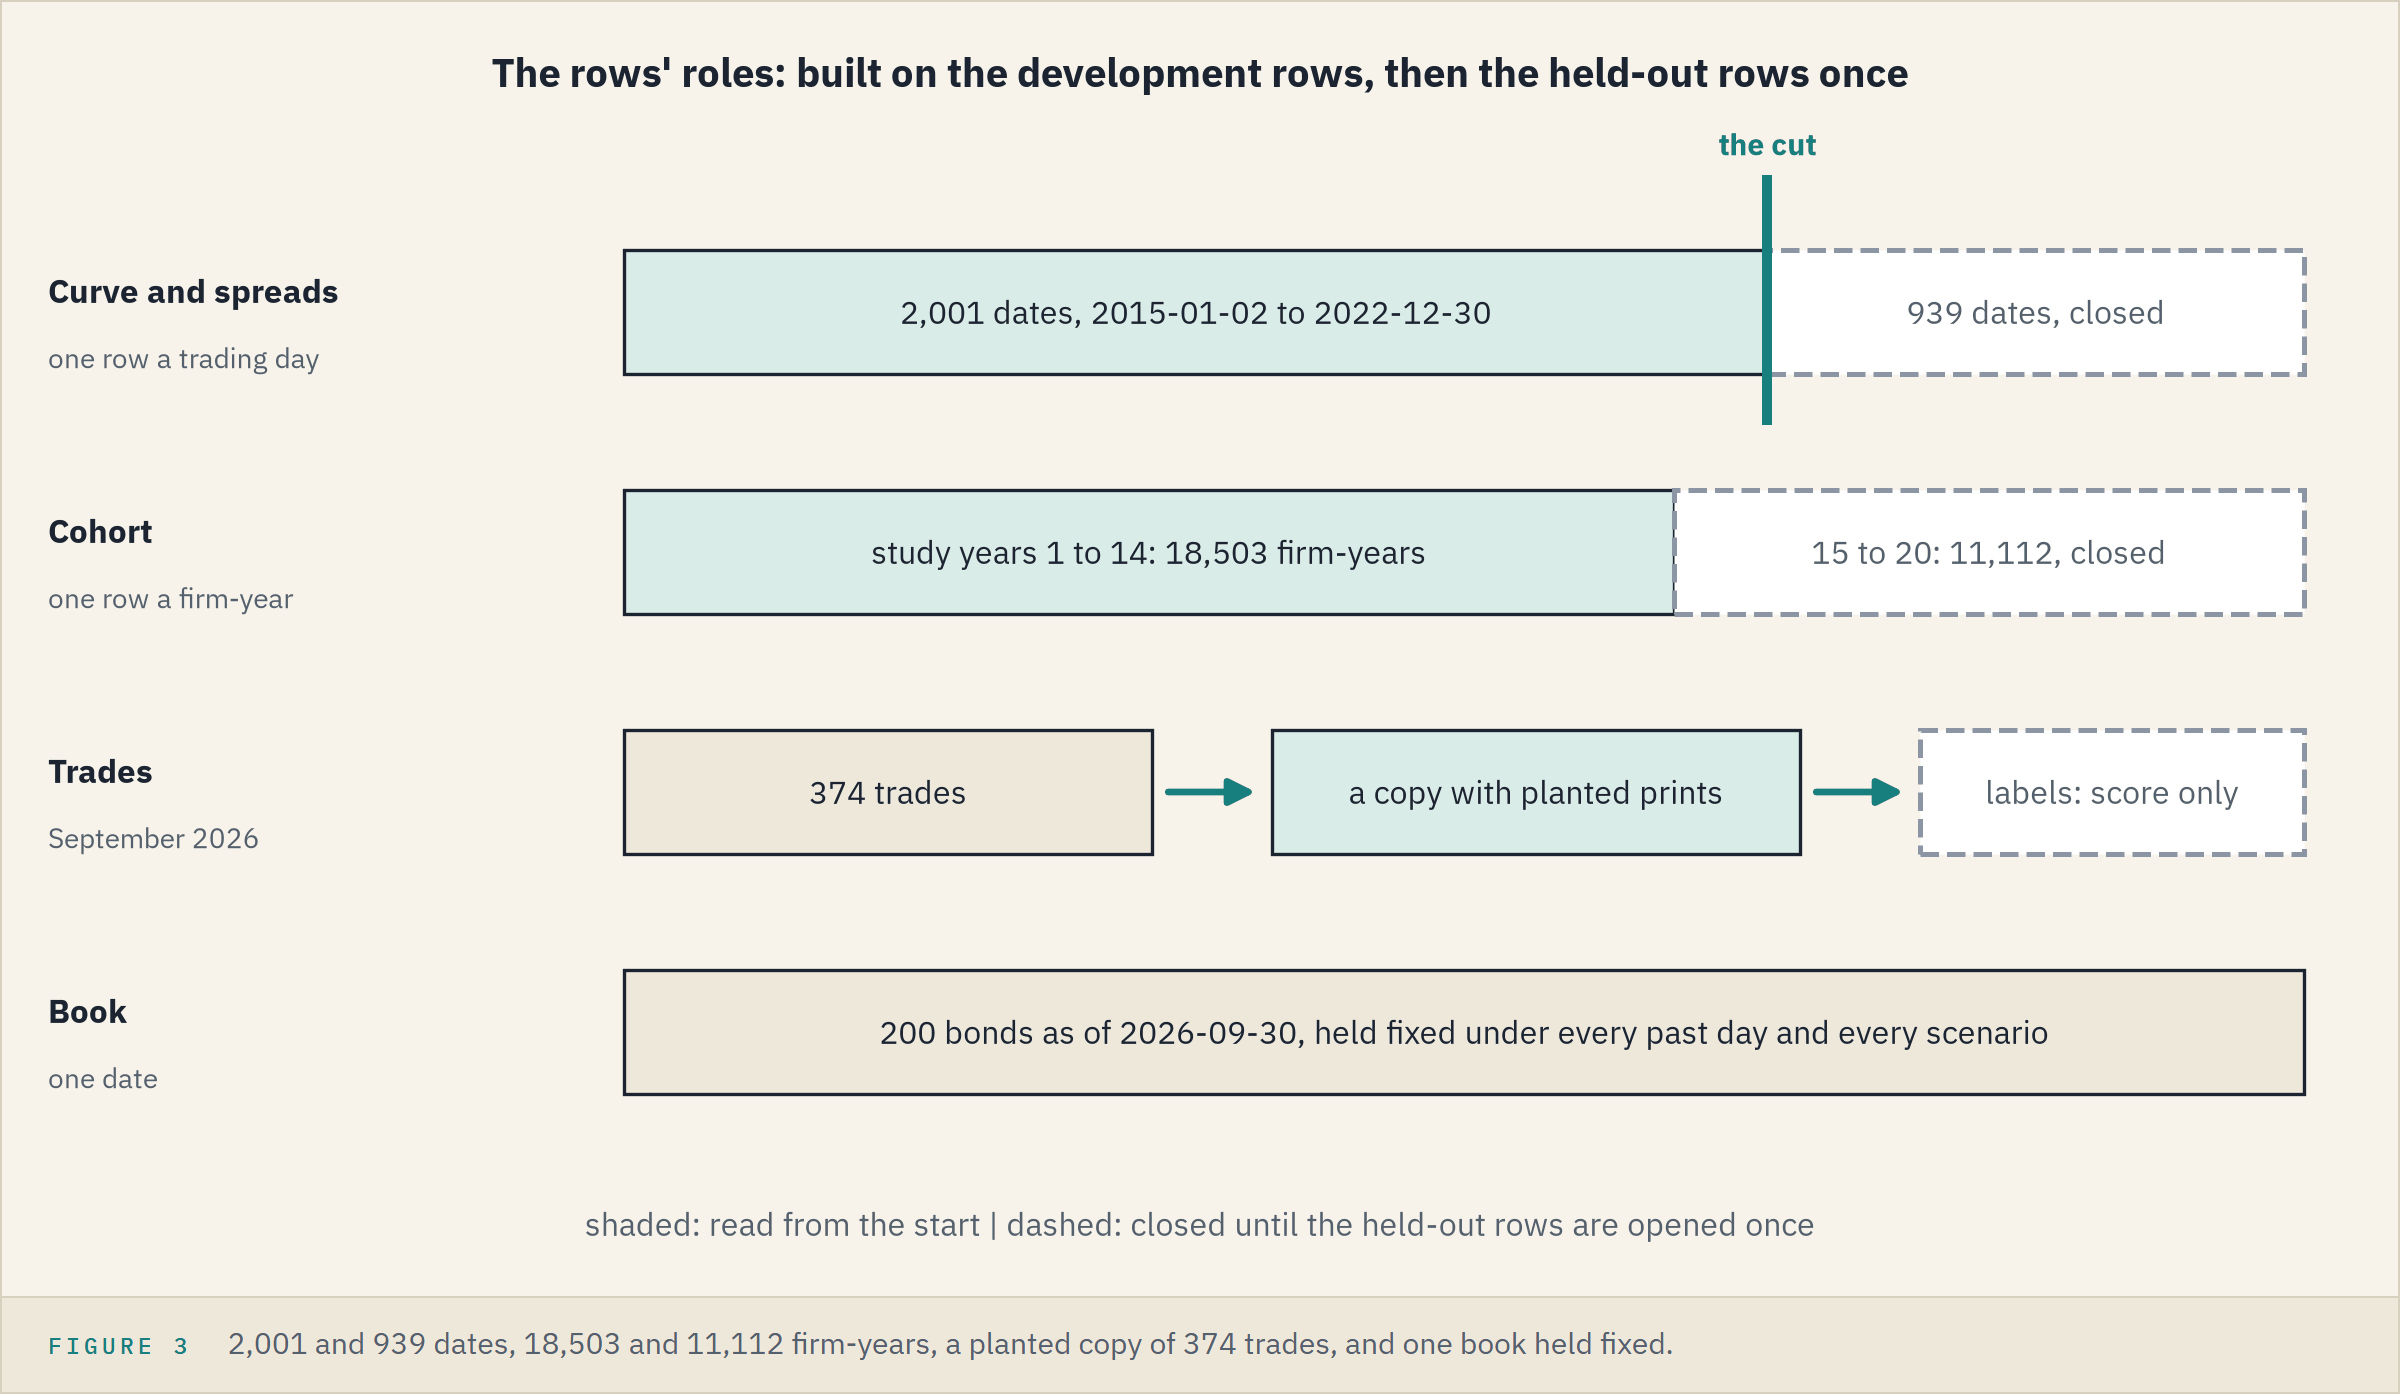

**Every held-out row stays closed until the choices are printed.**

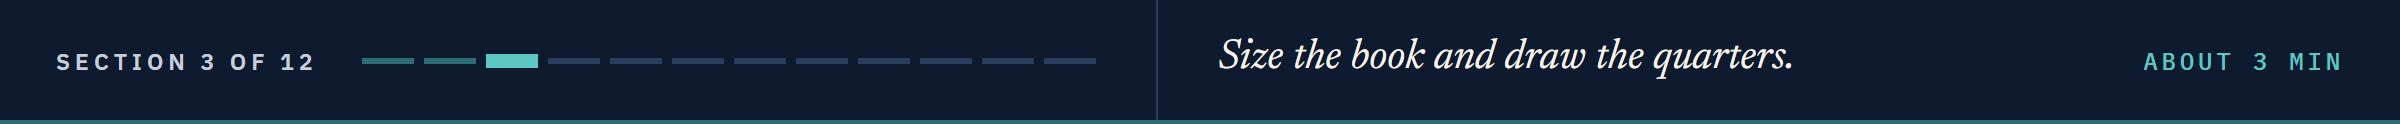

# Data Overview

## The Book and the Cohort

Q. Store the book's high-yield market value (US$) and its number of bonds: `q1_hy_value`, `q1_hy_bonds`.

Q. Store the development years' defaults and counted default rate (percent a year, 2 decimals): `q2_defaults`, `q2_rate`.

In [7]:
# your code here
q1_hy_value = ...
q1_hy_bonds = ...
q2_defaults = ...
q2_rate = ...

In [8]:
check("Q1 high-yield market value", q1_hy_value, "c12741dc394e", places=0)
check("Q1 high-yield bonds", q1_hy_bonds, "0eabafed2276", places=0)
check("Q2 development defaults", q2_defaults, "2c2b7062c81f", places=0)
check("Q2 counted default rate", q2_rate, "76894ddfba2c", places=2)

Q1 high-yield market value: not attempted yet
Q1 high-yield bonds: not attempted yet
Q2 development defaults: not attempted yet
Q2 counted default rate: not attempted yet


## The Development Curve, Quarter by Quarter

A **candlestick** draws a quarter as a wick from its lowest to its highest daily level, and a body from its first level to its last.
Day 8's `.index.to_period("Q")` names each day's quarter, and `groupby` gathers them.
The ruler is each tenor's nine decile edges of the development levels, cut now.

In [9]:
# each development quarter's first, highest, lowest and last daily level, for the 2 Yr and the 10 Yr
quarters = {tenor: dev_curve[tenor].groupby(dev_curve.index.to_period("Q")).agg(["first", "max", "min", "last"]) for tenor in [2, 10]}

# the ruler: each tenor's nine decile edges of the development levels, cut before any held-out value
ruler = {tenor: np.quantile(dev_curve[tenor], np.arange(1, 10) / 10) for tenor in [2, 10]}
closed = curve.index[curve.index > CUT].to_period("Q").nunique()
print(len(quarters[10]), "development quarters |", closed, "held-out quarters, closed")
for tenor in [2, 10]:
    print(f"{tenor} Yr: {dev_curve[tenor].min()} to {dev_curve[tenor].max()} percent | edges {ruler[tenor].round(2)}")

32 development quarters | 16 held-out quarters, closed
2 Yr: 0.09 to 4.72 percent | edges [0.16 0.41 0.67 0.8  1.21 1.45 1.8  2.45 2.76]
10 Yr: 0.52 to 4.25 percent | edges [0.95 1.54 1.71 1.87 2.12 2.27 2.42 2.75 2.97]


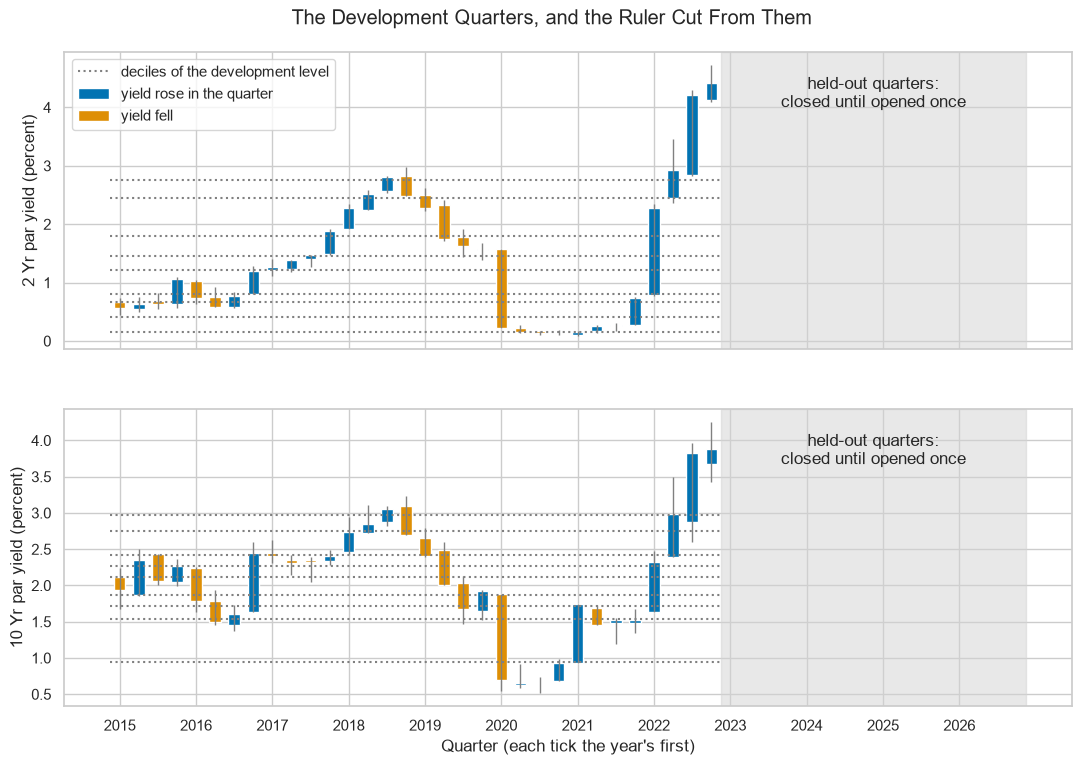

In [10]:
# a candlestick a quarter, the body coloured by direction; the ruler dotted; the held-out quarters a blank band
fig, axes = plt.subplots(2, 1, figsize=(13, 8.5), sharex=True)
for ax, tenor in zip(axes, [2, 10]):
    q, x = quarters[tenor], np.arange(len(quarters[tenor]))
    ax.vlines(x, q["min"], q["max"], color="gray", linewidth=1)
    for rose, colour, label in [(q["last"] >= q["first"], "C0", "yield rose in the quarter"), (q["last"] < q["first"], "C1", "yield fell")]:
        ax.bar(x[rose], (q["last"] - q["first"])[rose], bottom=q["first"][rose], width=0.6, color=colour, label=label)
    ax.hlines(ruler[tenor], -0.5, len(x) - 0.5, color="gray", linestyle=":", label="deciles of the development level")
    ax.axvspan(len(x) - 0.5, len(x) - 0.5 + closed, color="lightgray", alpha=0.5)
    # get_xaxis_transform: x in data, y as a share of the axis height
    ax.text(len(x) - 0.5 + closed / 2, 0.92, "held-out quarters:\nclosed until opened once", ha="center", va="top", transform=ax.get_xaxis_transform())
    ax.set(ylabel=f"{tenor} Yr par yield (percent)")
axes[0].legend(loc="upper left")
axes[1].set_xticks(np.arange(0, len(quarters[10]) + closed, 4), range(2015, 2027))
axes[1].set_xlabel("Quarter (each tick the year's first)")
fig.suptitle("The Development Quarters, and the Ruler Cut From Them", y=0.93)
plt.show()

The 10 Yr ran from 0.52 to 4.25 percent, the 2 Yr from 0.09 to 4.72.

By the end of 2022 both sat above every edge of their rulers.

**One book, one cohort, one month of trades, and a ruler fixed on the development years.**

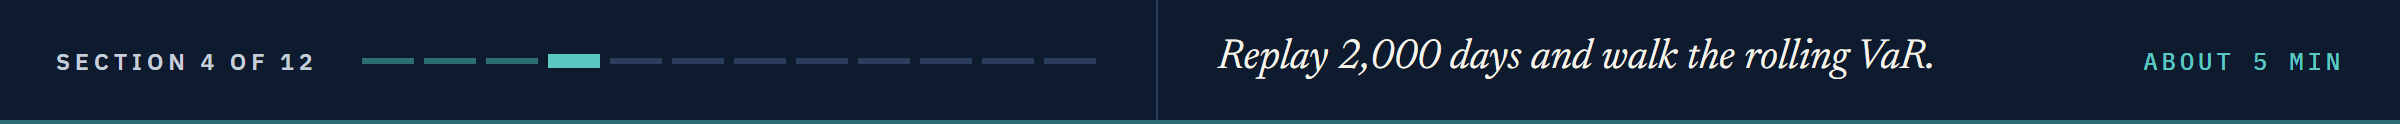

# The Book's Market Risk

Day 2's workflow, and one dictionary, `choices`, that takes each choice where it is made.

In [11]:
# every choice goes into one dictionary where it is made; it is printed before a held-out row is read
choices = {"VaR": {"levels": [0.95, 0.99], "fixed": "the development days", "rolling window": 500}}

## Two Lists of Sensitivities

Q. Repeat Day 2's key-rate DV01s (`key_rate_dv01`, by tenor in years) and DTS by index (`dts_by_index`, keyed by spread column). Store their sum and the HY DTS (US$): `q3_dv01`, `q3_hy_dts`.

In [12]:
# your code here
q3_dv01 = ...
q3_hy_dts = ...

In [13]:
check("Q3 key-rate DV01s", q3_dv01, "4976db78a16c", places=0)
check("Q3 HY DTS", q3_hy_dts, "c20556fe6aba", places=0)

Q3 key-rate DV01s: not attempted yet
Q3 HY DTS: not attempted yet


## 2,000 Days on Today's Book

Q. Replay the development days on the book as Day 2 did, `loss = -pnl` in US$, with Day 2's `var_es`. Store the 99 percent VaR and ES and the 95 percent VaR (US$): `q4_var99`, `q4_es99`, `q4_var95`.

In [14]:
# your code here
q4_var99 = ...
q4_es99 = ...
q4_var95 = ...

In [15]:
check("Q4 VaR 99", q4_var99, "26bc0660f971", places=0)
check("Q4 ES 99", q4_es99, "d45bc4a0b825", places=0)
check("Q4 VaR 95", q4_var95, "0bccbe62ef98", places=0)

Q4 VaR 99: not attempted yet
Q4 ES 99: not attempted yet
Q4 VaR 95: not attempted yet


## The Rolling VaR Inside Development

Q. Walk Day 2's rolling 500-day 99 percent VaR over the development losses, and run Day 2's `kupiec`. Store the exceptions and the p-value (4 decimals): `q5_exceptions`, `q5_p`.

Q. Draw the losses, the VaR and the exceptions, and the exceptions by year.

In [16]:
# your code here
q5_exceptions = ...
q5_p = ...

# then your chart

In [17]:
check("Q5 rolling exceptions", q5_exceptions, "b036e55290c8", places=0)
check("Q5 Kupiec p-value", q5_p, "0c0baeb8d2d7", places=4)

Q5 rolling exceptions: not attempted yet
Q5 Kupiec p-value: not attempted yet


**Two VaRs go forward, the fixed development one and the rolling one; the held-out days score both.**

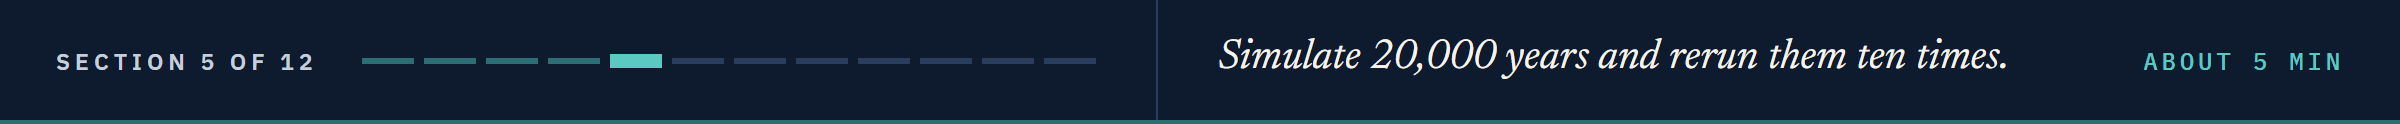

# The Book's Credit Loss

## A Default Probability for Every Bond

Q. Fit Day 3's pooled `sm.Logit` of `default` on `rating_score` as `pooled`, give each bond its `default_prob`, and take Day 3's expected loss at `LGD_MEAN = 0.60`. Store the slope and the mean probability in percent a year (4 decimals), and the expected loss (US$): `q6_slope`, `q6_mean_prob`, `q6_el`.

In [18]:
# your code here
q6_slope = ...
q6_mean_prob = ...
q6_el = ...

In [19]:
check("Q6 slope", q6_slope, "06fe4e018664", places=4)
check("Q6 mean probability", q6_mean_prob, "c91ed457426a", places=4)
check("Q6 expected loss", q6_el, "f895e048bb30", places=0)

Q6 slope: not attempted yet
Q6 mean probability: not attempted yet
Q6 expected loss: not attempted yet


## 20,000 Scenarios

Q. Repeat Day 3's `one_factor_defaults`, and write `credit_losses(default_prob, n_sims, rng)` at Day 3's `RHO = 0.20` and `rng.beta(6, 4)` LGDs. Run 20,000 scenarios from `default_rng(SEED)` as `losses`, and add the credit entry to `choices`. Store the mean and 99.9 percent VaR (US$), and the share with no default (3 decimals): `q7_mean`, `q7_var999`, `q7_none`.

A **quantile dot plot** stacks 100 dots, the quantiles at (i - 0.5) / 100, in US$1m bins: each dot is one chance in 100.

Q. Draw one for `losses`, the dots beyond the 99 percent VaR in the accent colour.

In [20]:
# your code here
q7_mean = ...
q7_var999 = ...
q7_none = ...

# then your chart

In [21]:
check("Q7 mean loss", q7_mean, "60297a3428d4", places=0)
check("Q7 VaR 99.9", q7_var999, "13e2bc74b37a", places=0)
check("Q7 share with no default", q7_none, "d8597cf79673", places=3)

Q7 mean loss: not attempted yet
Q7 VaR 99.9: not attempted yet
Q7 share with no default: not attempted yet


**Predict 1**

Day 3's ten runs of 50,000 put the standard deviation of the 99.9 percent VaR at US$0.91m.

Q. For ten runs of 20,000 with the same inputs, what standard deviation? Write down a number in US$ m.

## How Sure the 99.9 Percent Loss Is

Q. Rerun `credit_losses` ten times from `np.random.default_rng(SEED).spawn(10)`, a table `runs` of the VaR and ES at 99 and 99.9 percent (US$ m). Store the 99.9 percent VaR's standard deviation (US$): `q8_sd999`.

Q. Draw the runs as strips, Q7's run ringed.

In [22]:
# your code here
q8_sd999 = ...

# then your chart

In [23]:
check("Q8 sd of the 99.9 percent VaR", q8_sd999, "f478437051ba", places=0)

Q8 sd of the 99.9 percent VaR: not attempted yet


**At 20,000 scenarios read the 99.9 percent loss to about US$1.5m, never to the dollar.**

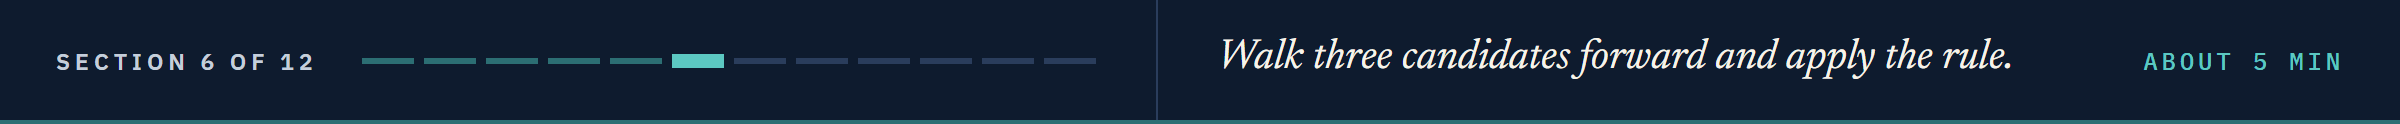

# Choosing the Hazard Model

## Three Candidates, Walked Forward

Q. Add Day 5's `log_coverage` and `early_years`, and walk three logistic hazards over test years 8 to 14, printing the years each trains on: rating only, three inputs (rating, leverage, log coverage), and Day 5's four. Keep the AUCs in `fold_auc`, a column a candidate. Store the four inputs' mean AUC, rating only's range, and its counted over fitted (4 decimals): `q9_four`, `q9_range`, `q9_ratio`.

Q. Draw the AUCs by test year, rating only's range shaded.

In [24]:
# your code here
q9_four = ...
q9_range = ...
q9_ratio = ...

# then your chart

In [25]:
check("Q9 four inputs mean AUC", q9_four, "b569398977be", places=4)
check("Q9 rating only range", q9_range, "187255038b4f", places=4)
check("Q9 rating only counted over fitted", q9_ratio, "a75ad9b899b2", places=4)

Q9 four inputs mean AUC: not attempted yet
Q9 rating only range: not attempted yet
Q9 rating only counted over fitted: not attempted yet


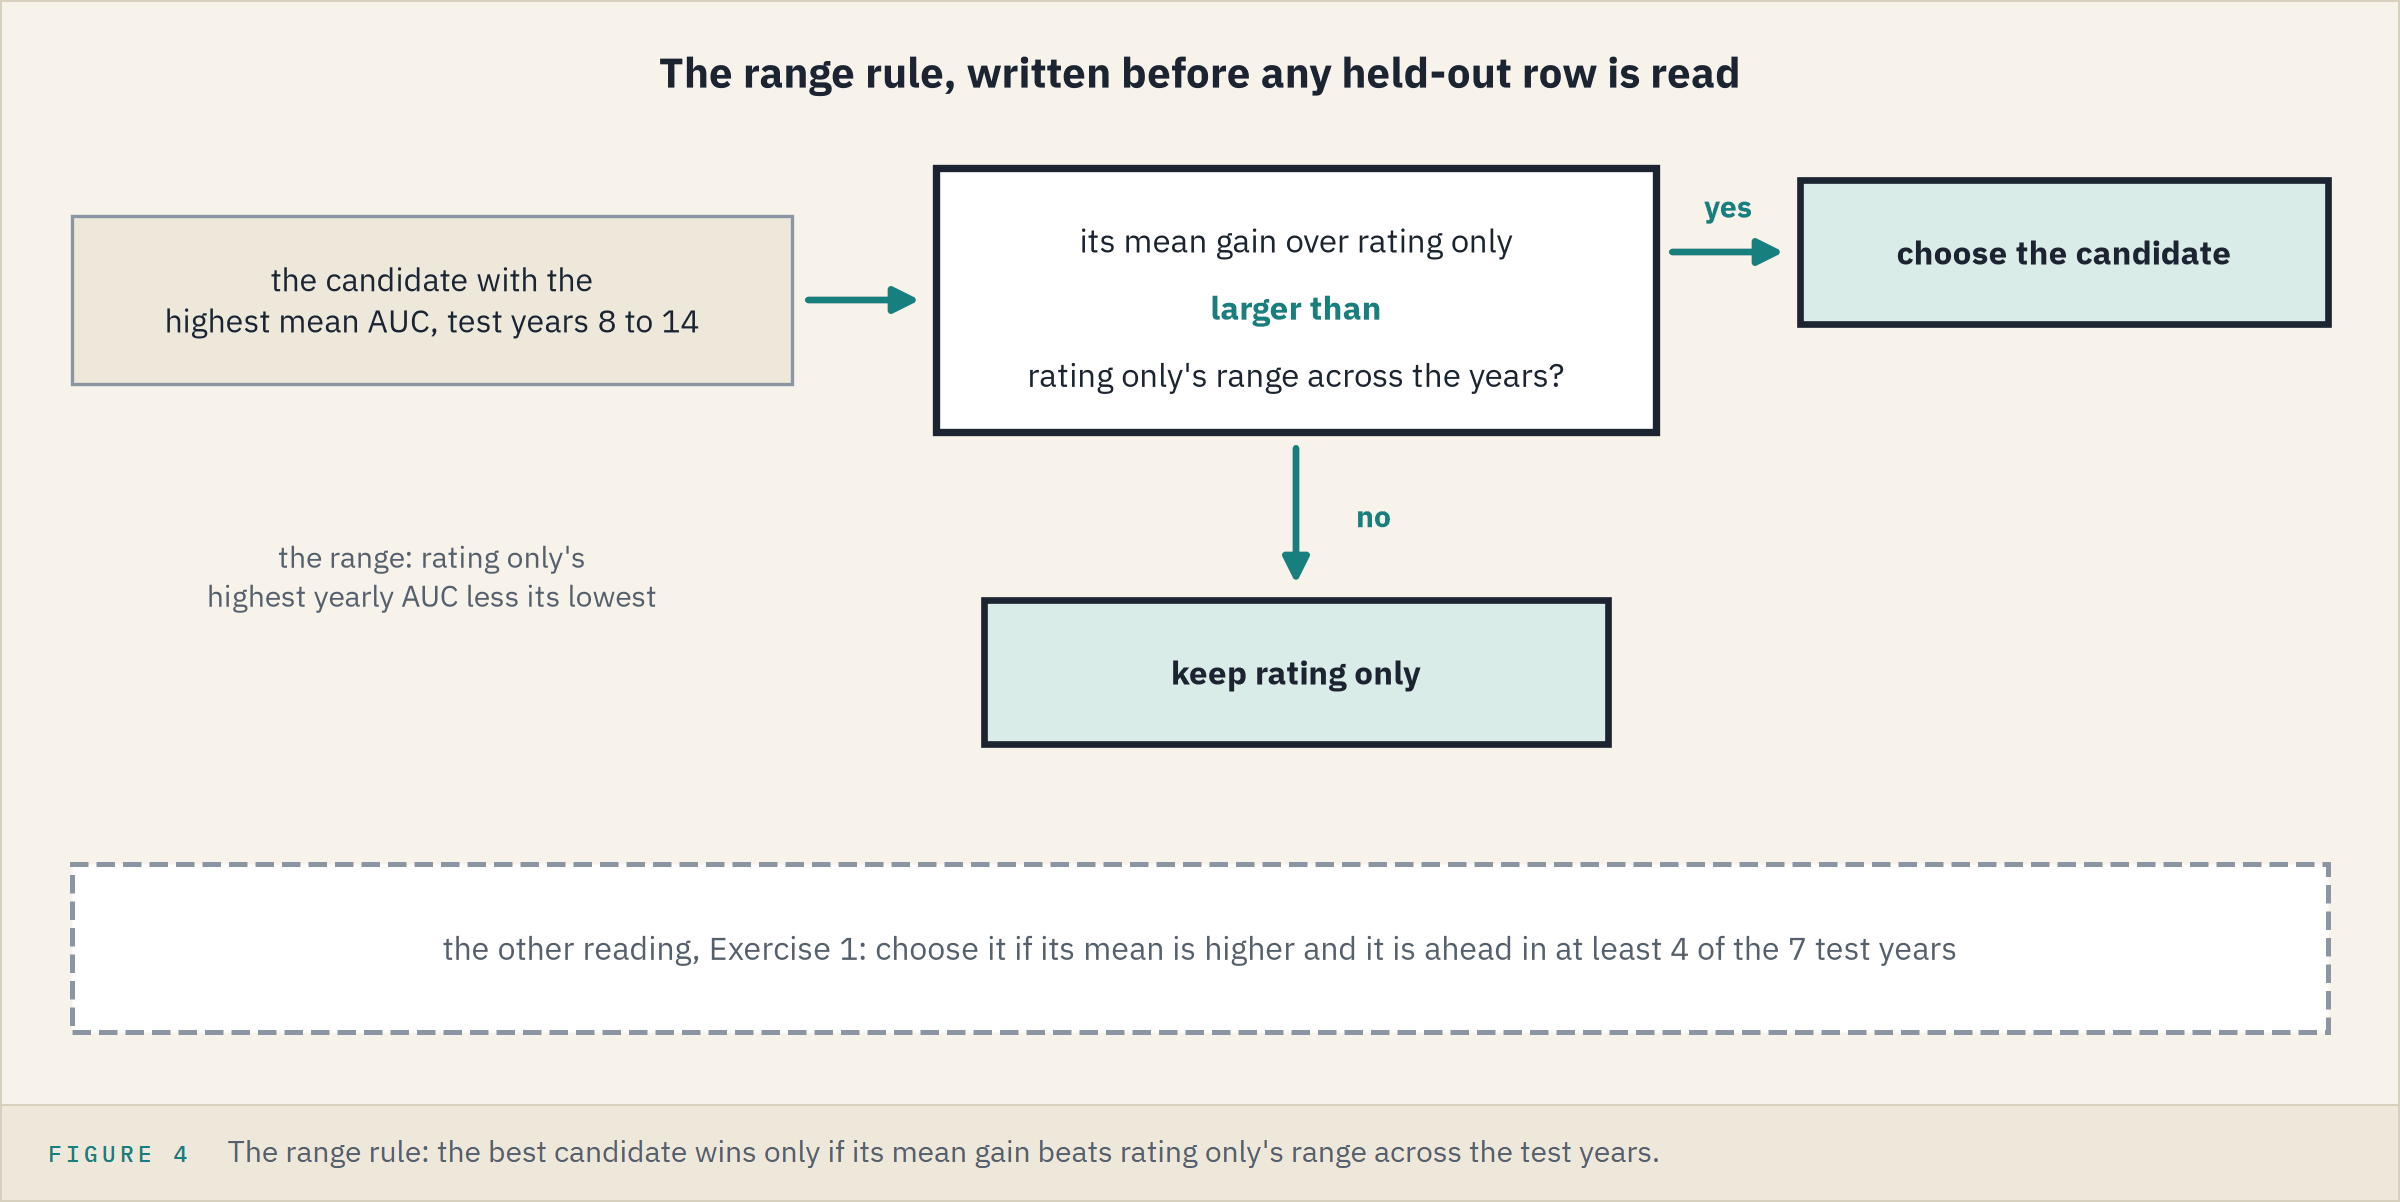

## The Rule, Written First

Q. Write `choose_by_range(fold_auc, baseline)`, Course 5B's range rule on AUC, apply it with `"rating only"` as the baseline, and add the hazard entry to `choices`. Store the choice: `q10_choice`.

In [26]:
# your code here
q10_choice = ...

In [27]:
check("Q10 the choice", q10_choice, "22030c58a316")

Q10 the choice: not attempted yet


## The Frozen Model

Q. The choice fitted on all the development firm-years is Q6's `pooled`: name it `frozen` and score `development["fitted"]`. Store the fitted sum (2 decimals) and the in-sample AUC (4 decimals): `q11_sum`, `q11_auc`.

In [28]:
# your code here
q11_sum = ...
q11_auc = ...

In [29]:
check("Q11 fitted sum", q11_sum, "ce0393563809", places=2)
check("Q11 in-sample AUC", q11_auc, "1a653c610fd8", places=4)

Q11 fitted sum: not attempted yet
Q11 in-sample AUC: not attempted yet


**The frozen hazard model and the book's default probabilities are one line, chosen before any held-out row.**

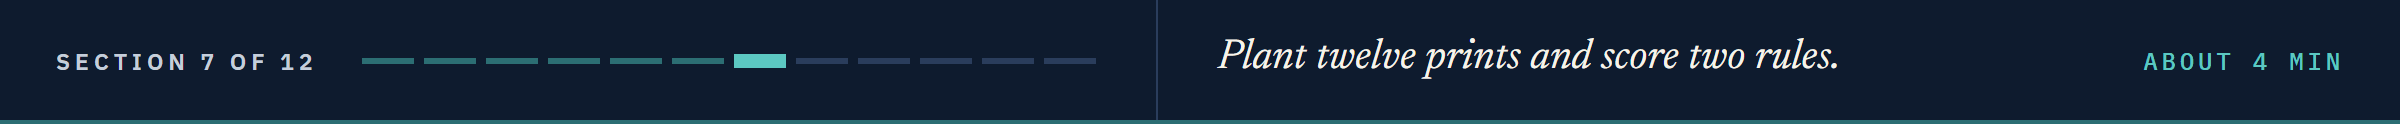

# The Anomaly Screen

## The Month With Planted Prints

Day 6's two published rules go into `choices` first, before the copy is made or a label read.

In [30]:
# Day 6's published rules: Iglewicz and Hoaglin's robust z above 3.5, and Tukey's outer fences
choices["screen"] = {"robust z above": 3.5, "outer fences k": 3}

# each trade's issuer, duration and month-end clean price from the book; then 12 planted prints, 9 moved 1.5 to 4 points, 3 slipped
trades = blotter.merge(book[["cusip", "issuer", "price", "duration"]].rename(columns={"price": "month_end_price"}), on="cusip", how="left")
rng = np.random.default_rng(SEED)
rows = rng.choice(len(blotter), 12, replace=False)
off_market, slipped = rows[:9], rows[9:]
prints = blotter.copy()
prints.loc[off_market, "price"] = (prints.loc[off_market, "price"] + rng.uniform(1.5, 4.0, 9) * rng.choice([-1.0, 1.0], 9)).round(3)
prints.loc[slipped, "price"] = (prints.loc[slipped, "price"] / 10).round(3)
planted = prints["price"] != blotter["price"]

In [31]:
# the 12 planted prints beside their true prices; the labels only score, and the copy is never written to disk
planted_table = trades.loc[planted, ["trade_id", "trade_date", "issuer", "duration", "price"]].rename(columns={"price": "true_price"})
planted_table["planted_price"] = prints.loc[planted, "price"]
planted_table["kind"] = np.where(planted_table.index.isin(slipped), "slipped decimal", "off-market")
planted_table

,trade_id,trade_date,issuer,duration,true_price,planted_price,kind
31,T0032,2026-09-02,Delvazor Paper,12.967,102.435,105.992,off-market
32,T0033,2026-09-02,Galvellix Paper,6.506,88.513,92.082,off-market
35,T0036,2026-09-02,Lorvane Systems,4.372,104.674,108.069,off-market
74,T0075,2026-09-08,Krilellix Networks,4.710,109.410,10.941,slipped decimal
158,T0159,2026-09-15,Zephiskan Resources,7.565,94.024,97.103,off-market
160,T0161,2026-09-15,Skelolvey Industrial,11.281,97.555,100.665,off-market
196,T0197,2026-09-16,Krilellix Networks,4.710,109.168,107.100,off-market
238,T0239,2026-09-21,Nevulex Health,4.846,103.617,106.503,off-market
258,T0259,2026-09-23,Feskebran Foods,5.183,99.437,9.944,slipped decimal
281,T0282,2026-09-24,Pellwick Paper,6.779,95.866,93.257,off-market


## Distance From the Month-End Price

Q. Measure Day 6's `distance` of each print in `prints` from its month-end price, in points per year of duration. Store its median and scaled MAD (4 decimals): `q12_median`, `q12_scaled_mad`.

In [32]:
# your code here
q12_median = ...
q12_scaled_mad = ...

In [33]:
check("Q12 median distance", q12_median, "6e7f7c1832fa", places=4)
check("Q12 scaled MAD", q12_scaled_mad, "9e186d49605b", places=4)

Q12 median distance: not attempted yet
Q12 scaled MAD: not attempted yet


**Predict 2**

On Day 6's 14 planted prints the robust z at 3.5 found 12.

Q. How many of these 12 does it find? Write down a number.

## Day 6's Two Rules

Q. Repeat Day 6's `screen_performance`, and flag a robust z above 3.5 and the prints outside the outer fences, rows in `screens`. Store the robust rule's flags and planted found, and the fences' flags: `q13_flags`, `q13_found`, `q13_fences`.

Q. Draw each trade's robust z on a symlog axis by kind, and the two confusion matrices in `CELL_COLOURS`.

In [34]:
# your code here
q13_flags = ...
q13_found = ...
q13_fences = ...

# then your chart

In [35]:
check("Q13 robust z flags", q13_flags, "3e4e49f530d3", places=0)
check("Q13 robust z planted found", q13_found, "0eb999cde837", places=0)
check("Q13 outer fence flags", q13_fences, "345630f7c210", places=0)

Q13 robust z flags: not attempted yet
Q13 robust z planted found: not attempted yet
Q13 outer fence flags: not attempted yet


**Per year of duration a long bond's move can hide inside the yardstick; a flag is a print to check, nothing more.**

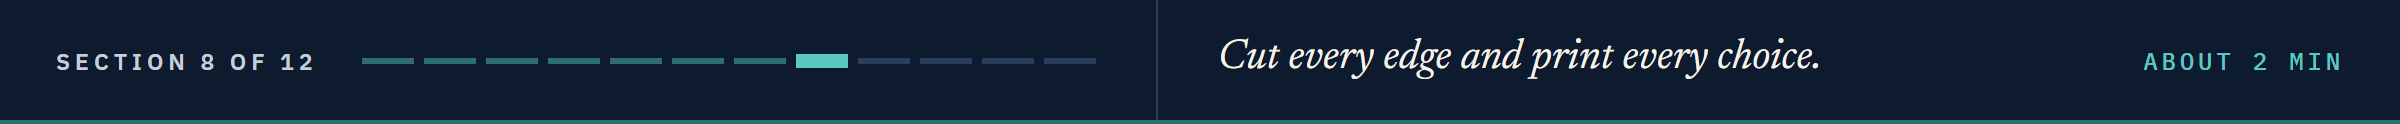

# Every Choice, Written First

## The Choices

Q. Repeat Day 8's three PSI functions, add the PSI settings and Day 9's bands to `choices`, and cut `EDGES` on development rows: every firm-year's `fitted` and three inputs, the entering firms' inputs (`"entrants leverage"`), and the 2 Yr and 10 Yr levels and whole-bp changes (`"2 Yr level"`, `"2 Yr change"`). Print `choices`, and store the edge sets: `q14_edges`.

In [36]:
# your code here
q14_edges = ...

In [37]:
check("Q14 edge sets", q14_edges, "f6728e6a488a", places=0)

Q14 edge sets: not attempted yet


**Every choice was written where it was made, and all of them are printed here, before the held-out rows.**

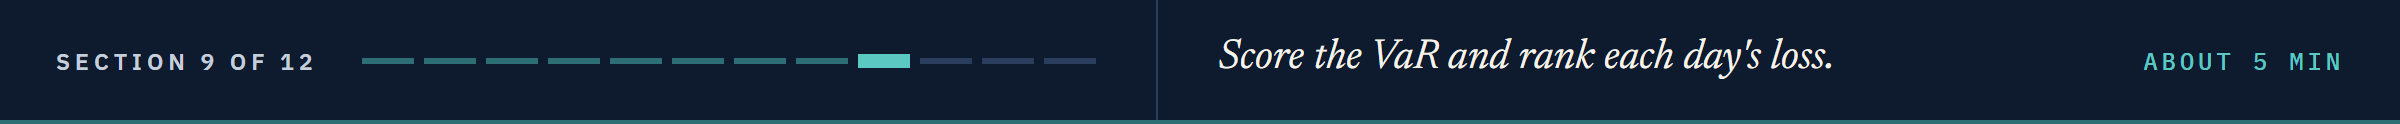

# The Held-Out Years, Opened Once

## Reading Them Once

In [38]:
# the held-out rows, read once: the curve after the cut, and study years 15 to 20
held_curve = curve.loc[curve.index > CUT]
held_out = cohort[cohort["study_year"] > DEVELOPMENT_END].copy()
print(len(held_curve), "dates,", held_curve.index[0].date(), "to", held_curve.index[-1].date(), "|", len(held_out), "firm-years")

939 dates, 2023-01-03 to 2026-10-02 | 11112 firm-years


## The Book on 939 New Days

Q. Replay every day from the full files, the first held-out move from the 2022-12-30 levels, as `all_loss` (US$), and keep `held_loss` after the cut. Store the held-out sd (US$) and the worst day (`YYYY-MM-DD`): `q15_sd`, `q15_worst`.

In [39]:
# your code here
q15_sd = ...
q15_worst = ...

In [40]:
check("Q15 held-out sd", q15_sd, "7f04300f3bfd", places=0)
check("Q15 worst day", q15_worst, "c2096cb4a95c")

Q15 held-out sd: not attempted yet
Q15 worst day: not attempted yet


**Predict 3**

Inside development the rolling 99 percent VaR was beaten 28 times in 1,500 days, against 15 expected.

Q. How many times on the 939 held-out days, against about 9.4 expected? Write down a number.

## The VaR, Scored Once

Q. Count the held-out exceptions of the fixed development VaR and the rolling 500-day VaR, each at 95 and 99 percent, with `kupiec`, a table `backtest`. Store the fixed and rolling 99 exceptions and the rolling 95 p-value (4 decimals): `q16_fixed99`, `q16_rolling99`, `q16_rolling95_p`.

Q. Draw the held-out losses, both 99 percent VaRs and their exceptions.

In [41]:
# your code here
q16_fixed99 = ...
q16_rolling99 = ...
q16_rolling95_p = ...

# then your chart

In [42]:
check("Q16 fixed 99 exceptions", q16_fixed99, "1aceb34e8abc", places=0)
check("Q16 rolling 99 exceptions", q16_rolling99, "756c533be912", places=0)
check("Q16 rolling 95 p-value", q16_rolling95_p, "e8454946c4ce", places=4)

Q16 fixed 99 exceptions: not attempted yet
Q16 rolling 99 exceptions: not attempted yet
Q16 rolling 95 p-value: not attempted yet


## Where Each Day Fell in Its Window

A **percentile-rank histogram** (a PIT histogram) ranks each day's loss in the 501 days to it, with Course 3's `.rolling(501).rank(pct=True, method="max")`, in 20 equal bins.
Windows like the days they score give flat counts.
`stats.binom.interval(0.95, n, 0.05)` holds the middle 95 percent of one bin's count, as Day 9's `stats.poisson.interval` held a year's defaults.

Q. Count the development ranks from 2017-01-03 and the held-out ranks. Store the held-out highest bin and the band's ends for 939 days: `q17_high_bin`, `q17_low`, `q17_high`.

Q. Draw both, each with its expected count and band.

In [43]:
# your code here
q17_high_bin = ...
q17_low = ...
q17_high = ...

# then your chart

In [44]:
check("Q17 held-out days in the highest bin", q17_high_bin, "4804814783bb", places=0)
check("Q17 band low", q17_low, "2a057627eae4", places=0)
check("Q17 band high", q17_high, "1269cd1cf37b", places=0)

Q17 held-out days in the highest bin: not attempted yet
Q17 band low: not attempted yet
Q17 band high: not attempted yet


**At 99 percent the VaR was beaten about as often as its level says; at 95 the rolling window held a busier past than the held-out days.**

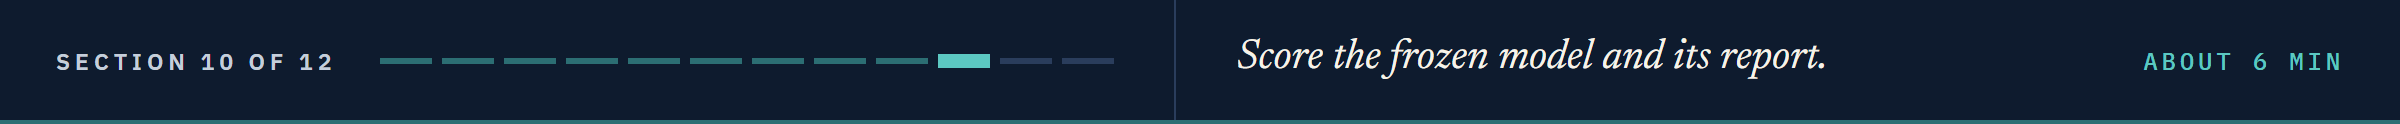

# Study Years 15 to 20, Scored Once

**Predict 4**

Walked forward over test years 8 to 14, rating only counted 0.9137 of its fitted defaults.

Q. Frozen on study years 1 to 14, what is its counted over fitted on 15 to 20 pooled? Write down a number.

## The Frozen Model, Year by Year

Q. Score `held_out` with `frozen`, add Day 5's features, and keep each year's counted, fitted, ratio and AUC in `held_years`. Store the pooled counted over fitted and AUC (4 decimals): `q18_ratio`, `q18_auc`.

Q. Draw Day 9's count ladder for study years 1 to 20.

In [45]:
# your code here
q18_ratio = ...
q18_auc = ...

# then your chart

In [46]:
check("Q18 pooled counted over fitted", q18_ratio, "7d5fb75efe95", places=4)
check("Q18 pooled AUC", q18_auc, "2f1a63e0bac4", places=4)

Q18 pooled counted over fitted: not attempted yet
Q18 pooled AUC: not attempted yet


## The Report Each Year

Q. Repeat Day 9's `monitoring_report` with `reference = development` (in-sample AUC), on each held-out year and the six pooled, reading `EDGES`. Store the years with the count red: `q19_red`.

Q. Draw Day 9's status grid.

In [47]:
# your code here
q19_red = ...

# then your chart

In [48]:
check("Q19 years with the count red", q19_red, "13dd6b6aacaf", places=0)

Q19 years with the count red: not attempted yet


## Defaults by Rating

Q. Count defaults against fitted by bucket, AAA to CCC, as `by_bucket`. Store the counted default rate of study years 15 to 20 (percent a year, 2 decimals) and B's counted over fitted (4 decimals): `q20_rate`, `q20_b`.

In [49]:
# your code here
q20_rate = ...
q20_b = ...

In [50]:
check("Q20 counted default rate", q20_rate, "869d84876cce", places=2)
check("Q20 B counted over fitted", q20_b, "a0c4fbf36df8", places=4)

Q20 counted default rate: not attempted yet
Q20 B counted over fitted: not attempted yet


**Predict 5**

At the development level one run of 20,000 put the 99.9 percent credit loss at US$36.2m.

Q. With every bond's probability scaled by the pooled counted over fitted of study years 15 to 20, what is it? Write down a number in US$ m.

## The Book's Credit Loss at the Counted Level

Q. Scale every bond's probability by `q18_ratio`, an input for the comparison, and run `credit_losses` once from `default_rng(SEED)` as `counted_losses`, then ten spawned times. Store the 99.9 percent VaR (US$) and its ratio to Q7's (3 decimals): `q21_var999`, `q21_times`.

Q. Draw both quantile dot plots on one axis.

In [51]:
# your code here
q21_var999 = ...
q21_times = ...

# then your chart

In [52]:
check("Q21 VaR 99.9 at the counted level", q21_var999, "83762ef7ad77", places=0)
check("Q21 ratio to the development run", q21_times, "1a4c1e154021", places=3)

Q21 VaR 99.9 at the counted level: not attempted yet
Q21 ratio to the development run: not attempted yet


**The defaults counted ran above the model's count while its order held; at that level the 99.9 percent loss grew by about a sixth.**

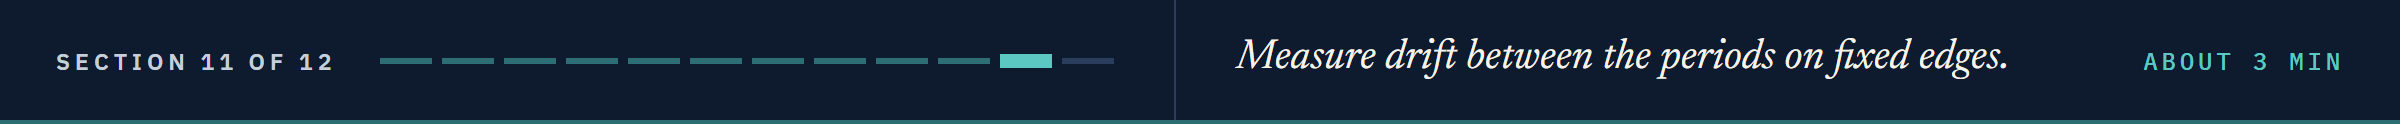

# The Two Periods, Compared by PSI

**Predict 6**

Inside development Day 8 found the 10 Yr level's PSI at 1.72 and its daily change's at 0.041.

Q. Held-out against development, on the development edges: the 10 Yr level's PSI, and its change's? Write down two numbers.

## The PSI Table

Q. With `psi` and `EDGES`, compute held-out against development for all eleven entries, in order, as `psi_table`. Store the 10 Yr level's, the 10 Yr change's and the entering firms' leverage's (4 decimals): `q22_level`, `q22_change`, `q22_entrants`.

Q. Draw `psi_table` as dots on a log axis, Day 8's two Yurdakul ends dotted.

In [53]:
# your code here
q22_level = ...
q22_change = ...
q22_entrants = ...

# then your chart

In [54]:
check("Q22 10 Yr level PSI", q22_level, "855d76e20d56", places=4)
check("Q22 10 Yr change PSI", q22_change, "928c15ce6d65", places=4)
check("Q22 entering firms' leverage PSI", q22_entrants, "649f05c820a1", places=4)

Q22 10 Yr level PSI: not attempted yet
Q22 10 Yr change PSI: not attempted yet
Q22 entering firms' leverage PSI: not attempted yet


## A Level Outside Its Ruler

Q. Read the 10 Yr level's held-out shares on its edges, the share above the development's highest level, and its PSI at floors 0.0001, 0.001 and 0.01. Store the share (3 decimals) and the PSI at 0.01 (2 decimals): `q23_above`, `q23_floor`.

Q. Redraw the candlesticks with all 48 quarters.

In [55]:
# your code here
q23_above = ...
q23_floor = ...

# then your chart

In [56]:
check("Q23 share above the development's highest", q23_above, "b830f7de1e25", places=3)
check("Q23 PSI at floor 0.01", q23_floor, "703e401517dc", places=2)

Q23 share above the development's highest: not attempted yet
Q23 PSI at floor 0.01: not attempted yet


**The levels left their ruler; the moves the VaR reads mostly did not, and the new firms moved while every firm-year stayed green.**

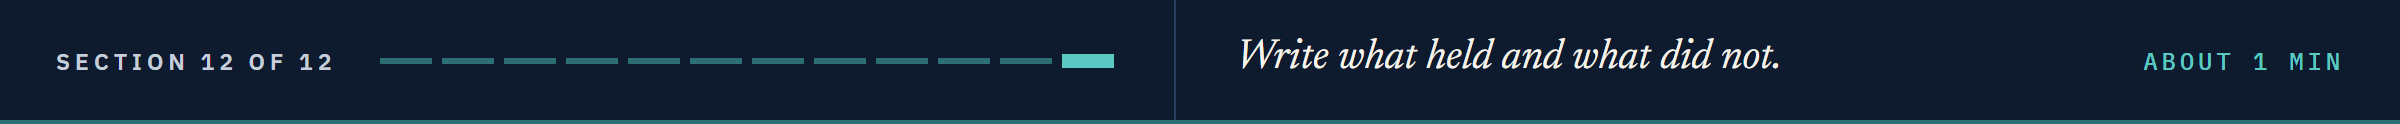

# Insights and Conclusion

## What the Models Show, and Where They Fail

Q. Write `description`: what held on the held-out rows, where each model failed, and what was not tested.

In [57]:
# your code here
description = ...

**A risk number describes the years it was built on; the held-out years said which ones held.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Run a historical VaR with its backtest, and a credit loss simulation with its percentiles' precision.
* Choose a model by a rule written before the held-out rows are read.
* Open held-out rows once, and score a VaR, a frozen model, a credit loss and drift there.
* Draw a candlestick, a percentile-rank histogram and a quantile dot plot.

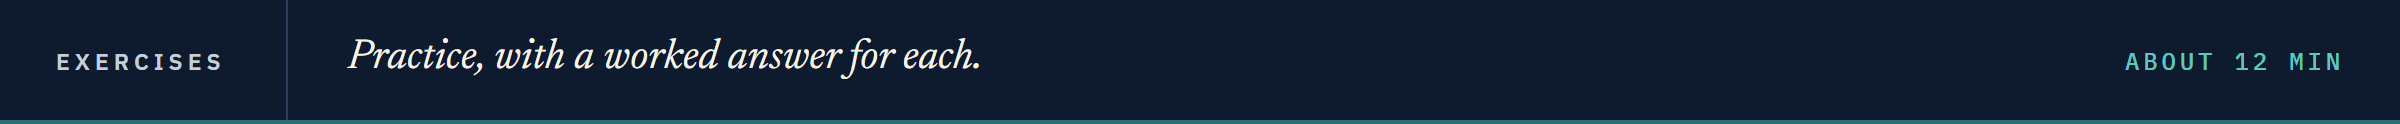

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

`check()` from Setting Up marks each answer.

### Exercise 1

**The Other Rule**

Q. Write `choose_by_folds(fold_auc, baseline, min_folds=4)`: the highest mean AUC if its mean beats the baseline's and it is ahead in at least `min_folds` test years, else the baseline. Store its choice on `fold_auc`, and that choice's held-out AUC when fitted on every development firm-year (4 decimals): `ex1_choice`, `ex1_auc`.

In [58]:
# your code here
ex1_choice = ...
ex1_auc = ...

In [59]:
check("Exercise 1 choice", ex1_choice, "304b187481c5")
check("Exercise 1 held-out AUC", ex1_auc, "f861a2289898", places=4)

Exercise 1 choice: not attempted yet
Exercise 1 held-out AUC: not attempted yet


### Exercise 2

**How Close the Exceptions Came**

Q. Write `gaps_between(flags)`, the trading days from each exception to the next in a boolean array. On the fixed development 99 percent VaR's held-out exceptions, store how many gaps are five trading days or fewer: `ex2_short`.

In [60]:
# your code here
ex2_short = ...

In [61]:
check("Exercise 2 short gaps", ex2_short, "0722a49e2187", places=0)

Exercise 2 short gaps: not attempted yet


### Exercise 3

**The Synthetic HY Spread**

Q. On edges cut on the development rows, store the PSI of the synthetic HY spread's level and of its whole-bp daily change, held-out against development (4 decimals): `ex3_level`, `ex3_change`.

In [62]:
# your code here
ex3_level = ...
ex3_change = ...

In [63]:
check("Exercise 3 HY level PSI", ex3_level, "fdb101b7d084", places=4)
check("Exercise 3 HY change PSI", ex3_change, "372540b05f11", places=4)

Exercise 3 HY level PSI: not attempted yet
Exercise 3 HY change PSI: not attempted yet


### Exercise 4: AI check

**Held-Out Exceptions**

You asked an AI assistant for a function that counts the held-out days beyond a VaR set on the development days.
This came back.
It runs.
Test it against its own docstring, then find the one bug.

In [64]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def held_out_exceptions(loss, cut, level):
    """The days after cut beyond the VaR of the days up to cut, and that VaR; the later losses never touch the VaR."""
    var = np.quantile(loss, level)
    return (loss[loss.index > cut] > var).sum(), var

Q. Run it on `all_loss` at 99 percent, then with every loss after the cut set to 0: by the docstring the VaR must not move. Fix the one wrong line and store the fixed function's exceptions: `ex4_exceptions`.

In [65]:
# your code here
ex4_exceptions = ...

In [66]:
check("Exercise 4 fixed exceptions", ex4_exceptions, "ff50335688df", places=0)

Exercise 4 fixed exceptions: not attempted yet


## Congratulations!

You built a whole risk report on the rows you were allowed to see, and wrote every choice down before the rest were opened.
Then you opened them once and said plainly what held and what did not.
A rule first and one look after is what makes a risk number worth reading.
Course 6 turns to neural networks, on the same habits.

[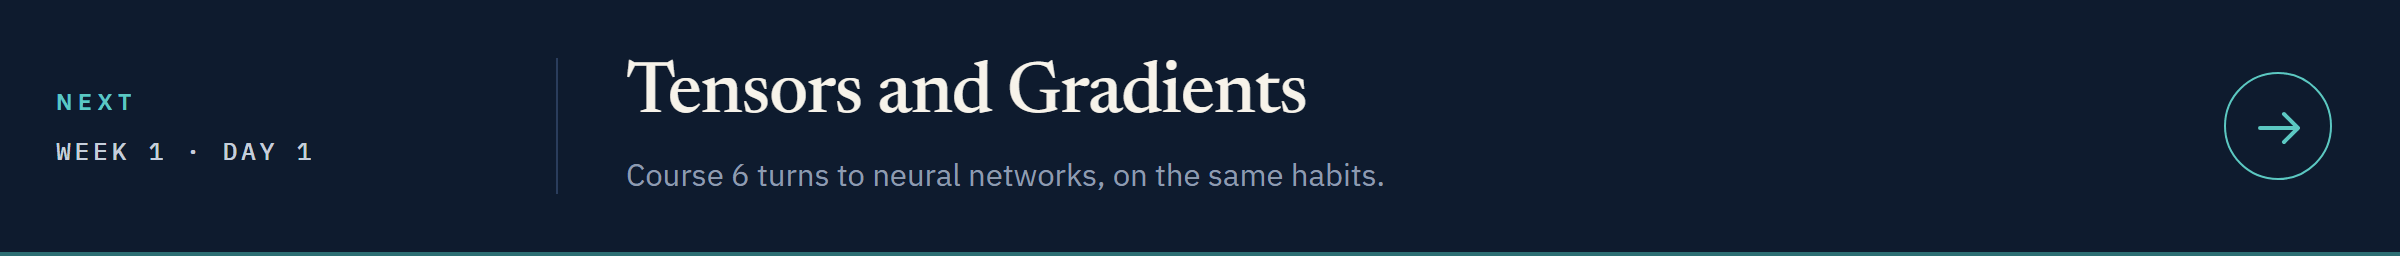](../../../course06_neural_networks/week1/day1/01_tensors_and_gradients.ipynb)

[Open Day 1 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course06_neural_networks/week1/day1/01_tensors_and_gradients.ipynb)